# 02 Limpeza normalização e treinamento

Este notebook repete a amostra de 20.000 registros do notebook 01, prepara
dez variáveis e treina um baseline simples. A saída é um CSV simplificado,
um pipeline salvo e os metadados necessários para a estratégia do notebook 03.

Execute primeiro o notebook 01 para interpretar as validações. Os notebooks
têm kernels independentes: este arquivo lê a origem e não depende de
variáveis deixadas em memória por outra execução.

**Ordem:** seleção → limpeza determinística → separação → ajuste do
pré-processamento no treino → validação → teste → persistência.

## 1 Ambiente e seleção reproduzível

Usamos somente scikit-learn para o baseline. O `ml_prep_kit` fornece
pré-processamento, fábrica de modelos e avaliação. As bibliotecas de drift
e tracking serão conectadas na implementação da estratégia proposta.

In [1]:
import hashlib
import json
import platform
import sys
from datetime import UTC, datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

In [2]:
project_root = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "requirements.txt").is_file()
        and (folder / "notebooks").is_dir()
        and (folder / "ml_prep_kit").is_dir()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("Abra o notebook dentro da pasta do projeto.")

raw_path = project_root / "data" / "raw" / "home-credit-default-risk"
train_file = raw_path / "application_train.csv"
if not train_file.is_file():
    raise FileNotFoundError(f"Arquivo de treinamento não encontrado: {train_file}")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from ml_prep_kit import FeaturePreprocessor, ModelEvaluator, ModelFactory

In [3]:
RANDOM_STATE = 42
SAMPLE_SIZE = 20_000
SELECTED_COLUMNS = [
    "SK_ID_CURR",
    "TARGET",
    "DAYS_BIRTH",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_HOUSING_TYPE",
    "CNT_CHILDREN",
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY",
]

source_columns = pd.read_csv(train_file, nrows=0).columns
missing_columns = set(SELECTED_COLUMNS).difference(source_columns)
if missing_columns:
    raise ValueError(f"Colunas obrigatórias ausentes: {sorted(missing_columns)}")

raw_df = pd.read_csv(train_file, usecols=SELECTED_COLUMNS)[SELECTED_COLUMNS]
if raw_df["SK_ID_CURR"].isna().any() or raw_df["SK_ID_CURR"].duplicated().any():
    raise ValueError("A base precisa ter identificadores preenchidos e únicos.")
if raw_df["TARGET"].isna().any() or set(raw_df["TARGET"].unique()) != {0, 1}:
    raise ValueError("TARGET deve conter as duas classes 0 e 1, sem nulos.")
if len(raw_df) < SAMPLE_SIZE:
    raise ValueError(f"São necessários pelo menos {SAMPLE_SIZE:,} registros.")

if len(raw_df) == SAMPLE_SIZE:
    sample_df = raw_df.copy()
else:
    sample_df, _ = train_test_split(
        raw_df,
        train_size=SAMPLE_SIZE,
        stratify=raw_df["TARGET"],
        random_state=RANDOM_STATE,
    )
sample_df = sample_df.sort_values("SK_ID_CURR").reset_index(drop=True)

## 2 Limpeza determinística e regras de entrada

Transformamos `DAYS_BIRTH` em `AGE_YEARS` e `Y/N` em `1/0`.
Removemos espaços nas categorias. Identificadores duplicados ou regras
violadas interrompem a execução para investigação, sem descarte silencioso.

A anuidade ausente é permitida nesta entrada e será imputada somente dentro
do pipeline. Valores extremos válidos são preservados. Não aplicamos cortes
aprendidos em toda a amostra, nem removemos linhas com base no alvo.

In [4]:
clean_df = sample_df.copy()
clean_df["AGE_YEARS"] = -clean_df.pop("DAYS_BIRTH") / 365.25
categorical_features = [
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_HOUSING_TYPE",
]
binary_features = ["FLAG_OWN_CAR", "FLAG_OWN_REALTY"]
numeric_features = [
    "AGE_YEARS",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "CNT_CHILDREN",
]
for column in categorical_features:
    clean_df[column] = clean_df[column].str.strip().astype(object)
for column in binary_features:
    clean_df[column] = clean_df[column].map({"Y": 1, "N": 0})

valid_rows = clean_df["AGE_YEARS"].between(18, 100)
for column in ["AMT_INCOME_TOTAL", "AMT_CREDIT"]:
    valid_rows &= clean_df[column].gt(0) & np.isfinite(clean_df[column])
valid_rows &= clean_df["AMT_ANNUITY"].isna() | (
    clean_df["AMT_ANNUITY"].gt(0) & np.isfinite(clean_df["AMT_ANNUITY"])
)
valid_rows &= clean_df["CNT_CHILDREN"].ge(0) & clean_df["CNT_CHILDREN"].mod(1).eq(0)
for column in categorical_features:
    valid_rows &= clean_df[column].notna() & clean_df[column].ne("")
for column in binary_features:
    valid_rows &= clean_df[column].isin([0, 1])
if not valid_rows.fillna(False).all():
    raise ValueError(
        f"{int((~valid_rows.fillna(False)).sum())} registros violam as regras. "
        "Investigue a origem antes de treinar."
    )
clean_df[binary_features] = clean_df[binary_features].astype("int64")
feature_columns = numeric_features + categorical_features + binary_features
clean_df = clean_df[["SK_ID_CURR", "TARGET", *feature_columns]]

display(
    pd.DataFrame(
        {
            "tipo": clean_df.dtypes.astype(str),
            "nulos_antes_da_imputação": clean_df.isna().sum(),
        }
    )
)
assert len(feature_columns) == 10
assert len(clean_df) == SAMPLE_SIZE

,tipo,nulos_antes_da_imputação
SK_ID_CURR,int64,0
TARGET,int64,0
AGE_YEARS,float64,0
AMT_INCOME_TOTAL,float64,0
AMT_CREDIT,float64,0
AMT_ANNUITY,float64,2
CNT_CHILDREN,int64,0
NAME_INCOME_TYPE,object,0
NAME_EDUCATION_TYPE,object,0
NAME_HOUSING_TYPE,object,0


## 3 Treino validação teste e produção separados

Reservamos **60% para treino, 10% para validação, 10% para teste e 20% para
produção simulada**. São divisões estratificadas, sem sobreposição de IDs.
Não representam períodos reais: a origem não oferece uma cronologia de
calendário para essa interpretação.

O treino aprende medianas, escalas, categorias e coeficientes. A validação
escolhe o limiar. O teste mede o resultado final. A produção fica reservada
para os cenários do Tech Challenge, sem avaliação do modelo neste notebook.

In [5]:
development_df, production_df = train_test_split(
    clean_df,
    test_size=0.20,
    stratify=clean_df["TARGET"],
    random_state=RANDOM_STATE,
)
train_df, evaluation_df = train_test_split(
    development_df,
    test_size=0.25,
    stratify=development_df["TARGET"],
    random_state=RANDOM_STATE,
)
validation_df, test_df = train_test_split(
    evaluation_df,
    test_size=0.50,
    stratify=evaluation_df["TARGET"],
    random_state=RANDOM_STATE,
)
partitions = {
    "treino": train_df,
    "validacao": validation_df,
    "teste": test_df,
    "producao": production_df,
}
partition_ids = {name: set(frame["SK_ID_CURR"]) for name, frame in partitions.items()}
for name, ids in partition_ids.items():
    for other_name, other_ids in partition_ids.items():
        if name != other_name:
            assert ids.isdisjoint(other_ids), "Há sobreposição entre conjuntos."
assert set.union(*partition_ids.values()) == set(clean_df["SK_ID_CURR"])
display(
    pd.DataFrame(
        [
            {
                "conjunto": name,
                "linhas": len(frame),
                "percentual": len(frame) / len(clean_df) * 100,
            }
            for name, frame in partitions.items()
        ]
    )
)

X_train, y_train = train_df[feature_columns], train_df["TARGET"]
X_validation, y_validation = validation_df[feature_columns], validation_df["TARGET"]
X_test, y_test = test_df[feature_columns], test_df["TARGET"]

,conjunto,linhas,percentual
0,treino,12000,60.0
1,validacao,2000,10.0
2,teste,2000,10.0
3,producao,4000,20.0


## 4 Pré processamento e baseline

O `FeaturePreprocessor` aplica mediana e **MinMaxScaler** às variáveis
numéricas, moda e **one-hot encoding** às categóricas, e mantém as binárias.
Ele é ajustado apenas por `pipeline.fit(X_train, y_train)`.

Min-Max usa os extremos do treino. Uma entrada futura pode ficar fora de
`[0, 1]`; isso não deve ser ocultado por um reajuste da escala em produção.
Categorias desconhecidas são toleradas pelo encoder e precisarão de monitoramento.

Comparamos uma referência `DummyClassifier` com **regressão logística**.
`class_weight="balanced"` compensa o desbalanceamento no ajuste. Os scores
não serão apresentados como probabilidades calibradas de risco.

In [6]:
factory = ModelFactory(random_state=RANDOM_STATE)
model_specs = {
    "dummy": ("dummy", {"strategy": "prior"}),
    "logistic_regression": (
        "logistic_regression",
        {"max_iter": 2_000, "class_weight": "balanced"},
    ),
}
models = {}
for name, (model_name, parameters) in model_specs.items():
    preprocessor = FeaturePreprocessor(
        numeric_columns=numeric_features,
        categorical_columns=categorical_features,
        binary_columns=binary_features,
    ).create_pipeline()
    pipeline = factory.create_pipeline(
        preprocessor=preprocessor,
        problem_type="classification",
        model_name=model_name,
        parameters=parameters,
    )
    pipeline.fit(X_train, y_train)
    models[name] = pipeline

trained_pipeline = models["logistic_regression"]
transformed_train = trained_pipeline.named_steps["preprocessor"].transform(X_train)
assert np.isfinite(transformed_train.to_numpy()).all()
print(f"Features de entrada: {X_train.shape[1]}")
print(f"Features após encoding: {transformed_train.shape[1]}")

Features de entrada: 10
Features após encoding: 24


## 5 Avaliação na validação e escolha do limiar

ROC AUC mede ordenação; **Average Precision** resume a curva precisão-recall
e deve ser comparada à proporção de positivos. Acurácia isolada pode ocultar
a falta de detecção da classe minoritária.

Para a demonstração, escolhemos o maior F1 em uma grade de limiares usando
apenas validação. Esse é um critério técnico inicial, não uma política de
concessão de crédito ou uma otimização de custos financeiros.

,roc_auc,average_precision,precision,recall,f1,balanced_accuracy
dummy,0.500000,0.081000,NaN,0.000000,0.000000,0.50000
logistic_regression,0.633737,0.129899,0.123675,0.648148,0.207715,0.62168


,threshold,precision,recall,f1,specificity,false_positives,false_negatives
9,0.50,0.123675,0.648148,0.207715,0.595212,744,57
10,0.55,0.132969,0.450617,0.205345,0.741023,476,89
11,0.60,0.147335,0.290123,0.195426,0.852013,272,115
8,0.45,0.103139,0.709877,0.180110,0.455930,1000,47
7,0.40,0.095272,0.833333,0.170994,0.302503,1282,27
12,0.65,0.170213,0.148148,0.158416,0.936344,117,138
6,0.35,0.086093,0.882716,0.156884,0.174102,1518,19
5,0.30,0.082873,0.925926,0.152130,0.096844,1660,12
0,0.05,0.081000,1.000000,0.149861,0.000000,1838,0
1,0.10,0.081000,1.000000,0.149861,0.000000,1838,0


Limiar escolhido somente na validação: 0.50


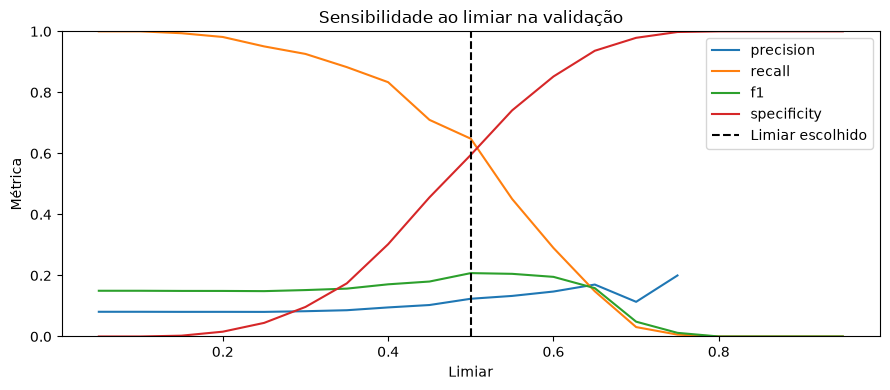

In [7]:
evaluator = ModelEvaluator()
evaluation_figures = {}


def positive_scores(pipeline, features):
    positive_index = list(pipeline.classes_).index(1)
    return pipeline.predict_proba(features)[:, positive_index]


def evaluate_pipeline(pipeline, features, target, threshold=0.5):
    return evaluator.evaluate_binary_classification(
        target, positive_scores(pipeline, features), threshold=threshold
    )["metrics"]


validation_metrics = {
    name: evaluate_pipeline(pipeline, X_validation, y_validation)
    for name, pipeline in models.items()
}
display(
    pd.DataFrame(validation_metrics).T[
        [
            "roc_auc",
            "average_precision",
            "precision",
            "recall",
            "f1",
            "balanced_accuracy",
        ]
    ]
)
validation_scores = positive_scores(trained_pipeline, X_validation)
threshold_results = pd.DataFrame(
    [
        evaluator.evaluate_binary_classification(
            y_validation, validation_scores, threshold=float(threshold)
        )["metrics"]
        for threshold in np.arange(0.05, 1.0, 0.05)
    ]
).sort_values(["f1", "recall", "threshold"], ascending=[False, False, True])
selected_threshold = float(threshold_results.iloc[0]["threshold"])
display(
    threshold_results[
        [
            "threshold",
            "precision",
            "recall",
            "f1",
            "specificity",
            "false_positives",
            "false_negatives",
        ]
    ]
)
print(f"Limiar escolhido somente na validação: {selected_threshold:.2f}")

fig, ax = plt.subplots(figsize=(9, 4))
threshold_results.sort_values("threshold").plot(
    x="threshold", y=["precision", "recall", "f1", "specificity"], ax=ax
)
ax.axvline(selected_threshold, color="black", linestyle="--", label="Limiar escolhido")
ax.set(
    title="Sensibilidade ao limiar na validação",
    xlabel="Limiar",
    ylabel="Métrica",
    ylim=(0, 1),
)
ax.legend()
fig.tight_layout()
evaluation_figures["threshold_sensitivity"] = fig
plt.show()

## 6 Avaliação final no teste reservado

Modelo e limiar estão fixados antes desta avaliação. Se os resultados forem
limitados, isso será registrado como limitação do baseline, sem ajustar
novamente o modelo a partir deste teste. A próxima fase monitora esse modelo
congelado; o desafio não exige vencer a competição do Kaggle.

In [8]:
evaluation_sets = {
    "treino": (X_train, y_train),
    "validacao": (X_validation, y_validation),
    "teste": (X_test, y_test),
}
evaluation_reports = {}
evaluation_scores = {}
global_rows = []
for name, pipeline in models.items():
    evaluation_reports[name] = {}
    evaluation_scores[name] = {}
    model_threshold = selected_threshold if name == "logistic_regression" else 0.5
    for split, (features, target) in evaluation_sets.items():
        scores = positive_scores(pipeline, features)
        report = evaluator.evaluate_binary_classification(
            target, scores, threshold=model_threshold
        )
        evaluation_scores[name][split] = scores
        evaluation_reports[name][split] = report
        global_rows.append({"model": name, "split": split, **report["metrics"]})

global_metrics = pd.DataFrame(global_rows).set_index(["model", "split"])
test_metrics = {name: evaluation_reports[name]["teste"]["metrics"] for name in models}
# Todas as métricas, inclusive macro, weighted, contagens e taxas de erro.
display(pd.DataFrame(test_metrics).rename_axis("métrica").round(4))
display(
    global_metrics[
        [
            "sample_size",
            "roc_auc",
            "average_precision",
            "precision",
            "recall",
            "f1",
            "balanced_accuracy",
            "brier_score",
            "log_loss",
        ]
    ].round(4)
)
class_metrics = pd.concat(
    [
        report["teste"]["by_class"].assign(model=name)
        for name, report in evaluation_reports.items()
    ],
    ignore_index=True,
)
display(class_metrics[["model", "class", "precision", "recall", "f1", "support"]])

,dummy,logistic_regression
métrica,,
accuracy,0.9195,0.5970
precision,NaN,0.1183
recall,0.0000,0.6211
f1,0.0000,0.1988
precision_macro,0.4598,0.5328
recall_macro,0.5000,0.6080
f1_macro,0.4790,0.4648
precision_weighted,0.8455,0.8805
recall_weighted,0.9195,0.5970


sample_size  roc_auc  average_precision  \
model               split                                                
dummy               treino           12000   0.5000             0.0808   
                    validacao         2000   0.5000             0.0810   
                    teste             2000   0.5000             0.0805   
logistic_regression treino           12000   0.6383             0.1251   
                    validacao         2000   0.6337             0.1299   
                    teste             2000   0.6279             0.1164   

                               precision  recall      f1  balanced_accuracy  \
model               split                                                     
dummy               treino           NaN  0.0000  0.0000             0.5000   
                    validacao        NaN  0.0000  0.0000             0.5000   
                    teste            NaN  0.0000  0.0000             0.5000   
logistic_regression treino        0.1122  0.5965  0.1888             0.5909   
                    validacao     0.1237  0.6481  0.2077             0.6217   
                    teste         0.1183  0.6211  0.1988             0.6080   

                               brier_score  log_loss  
model               split                             
dummy               treino          0.0742    0.2806  
                    validacao       0.0744    0.2812  
                    teste           0.0740    0.2800  
logistic_regression treino          0.2359    0.6632  
                    validacao       0.2328    0.6571  
                    teste           0.2355    0.6624

,model,class,precision,recall,f1,support
0,dummy,0,0.919500,1.000000,0.958062,1839
1,dummy,1,0.000000,0.000000,0.000000,161
2,logistic_regression,0,0.947186,0.594889,0.730795,1839
3,logistic_regression,1,0.118343,0.621118,0.198807,161


### 6.1 Como interpretar a avaliação completa

Todos os cálculos passam pelo `ModelEvaluator`, incluindo sua tabela por
classe. `TARGET = 1` é a classe de dificuldade de pagamento. Matrizes têm
**linhas reais e colunas previstas**. Precisão sem nenhuma predição positiva
aparece como indisponível; na tabela por classe, mantém-se a convenção
`zero_division=0`. Valores ausentes em métricas não são convertidos em sucesso.

A comparação treino/validação/teste ajuda a identificar perda de generalização.
Resultados de treino são descritivos e otimistas. O limiar da regressão foi
escolhido na validação; o Dummy mantém 0,5. Não há escolha ou ajuste com o teste.

- **Recall e falsos negativos:** quantos casos de dificuldade foram detectados ou perdidos.
- **Precisão e falsos positivos:** quantos alertas correspondem a dificuldades reais.
- **Especificidade:** proporção de negativos corretamente classificados.
- **Balanced accuracy e MCC:** complementam a acurácia na base desbalanceada.
- **ROC AUC e Average Precision:** capacidade de ordenar os casos por score.
- **Brier score e log loss:** erros das probabilidades; valores menores são melhores.
- **Macro e weighted:** visão das duas classes com pesos iguais ou segundo o suporte.

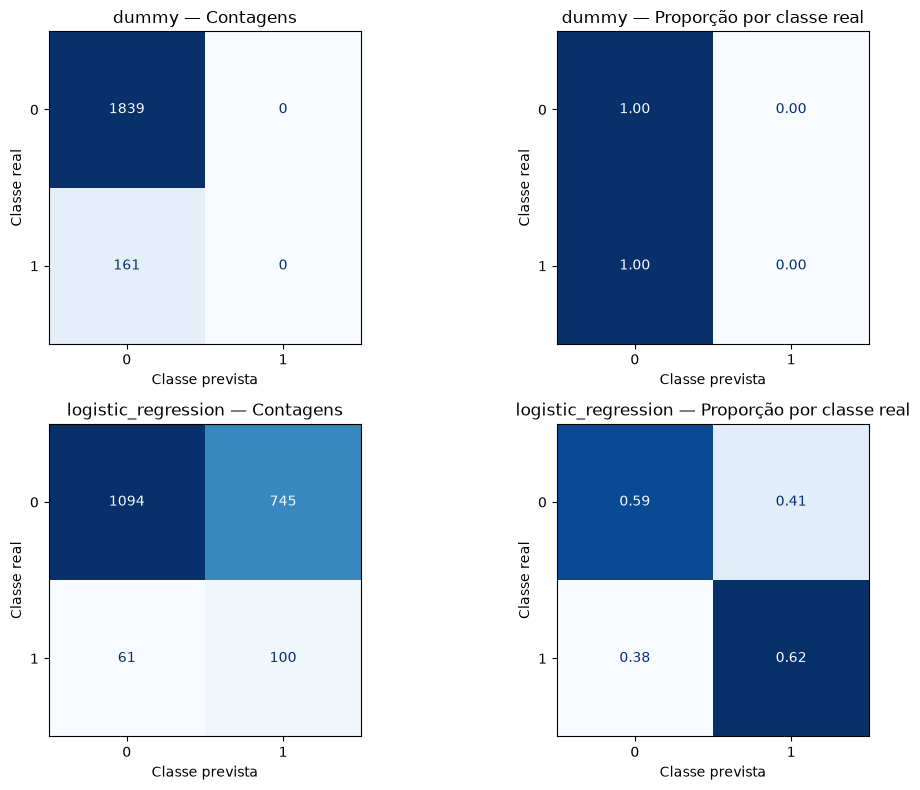

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for row, name in enumerate(models):
    matrix = evaluation_reports[name]["teste"]["confusion_matrix"].to_numpy()
    normalized = matrix / matrix.sum(axis=1, keepdims=True)
    for column, (values, title) in enumerate(
        [(matrix, "Contagens"), (normalized, "Proporção por classe real")]
    ):
        ConfusionMatrixDisplay(values, display_labels=[0, 1]).plot(
            ax=axes[row, column],
            colorbar=False,
            cmap="Blues",
            values_format="d" if column == 0 else ".2f",
        )
        axes[row, column].set(
            title=f"{name} — {title}", xlabel="Classe prevista", ylabel="Classe real"
        )
fig.tight_layout()
evaluation_figures["confusion_matrices"] = fig
plt.show()

### 6.2 Curvas ROC e precisão recall

A curva ROC compara detecção da classe positiva e falsos positivos.
A curva precisão-recall mostra o custo em precisão ao buscar maior cobertura.
Average Precision é calculada pelo avaliador e não por integração trapezoidal.
Sua referência é a prevalência positiva do teste, não 0,5.

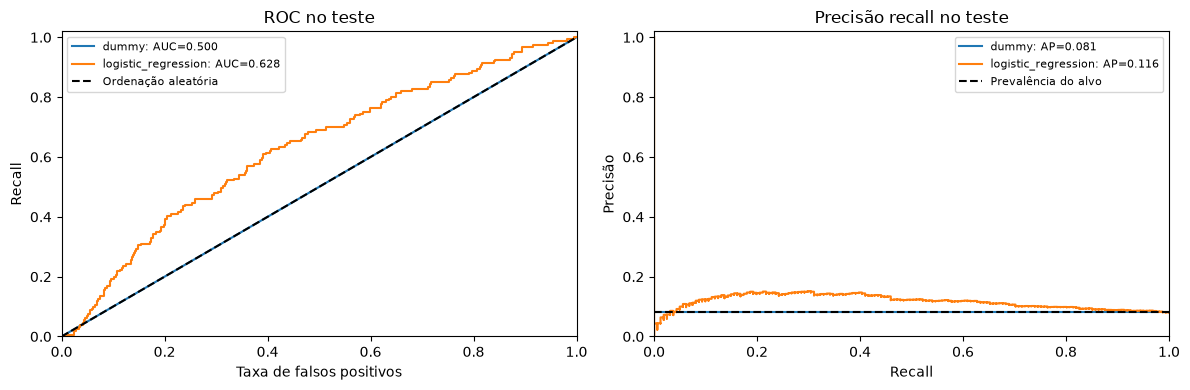

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in models:
    report = evaluation_reports[name]["teste"]
    metrics = report["metrics"]
    roc = report["roc_curve"]
    pr = report["precision_recall_curve"]
    axes[0].plot(
        roc["false_positive_rate"],
        roc["true_positive_rate"],
        label=f"{name}: AUC={metrics['roc_auc']:.3f}",
    )
    axes[1].step(
        pr["recall"],
        pr["precision"],
        where="post",
        label=f"{name}: AP={metrics['average_precision']:.3f}",
    )
axes[0].plot([0, 1], [0, 1], "k--", label="Ordenação aleatória")
axes[1].axhline(
    float(y_test.mean()), color="black", linestyle="--", label="Prevalência do alvo"
)
axes[0].set(title="ROC no teste", xlabel="Taxa de falsos positivos", ylabel="Recall")
axes[1].set(title="Precisão recall no teste", xlabel="Recall", ylabel="Precisão")
for ax in axes:
    ax.set(xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(fontsize=8)
fig.tight_layout()
evaluation_figures["roc_precision_recall"] = fig
plt.show()

### 6.3 Calibração e distribuição dos scores

Agrupamos probabilidades em dez intervalos uniformes e mostramos apenas os
intervalos ocupados, com seu suporte. A diagonal representa concordância
entre score médio e frequência observada. O Dummy pode ser bem calibrado
em média e ainda não distinguir pessoas de maior e menor risco.

O ajuste com `class_weight="balanced"` não garante probabilidades calibradas.
Esta avaliação diagnostica o problema; não recalibra o modelo usando o teste.

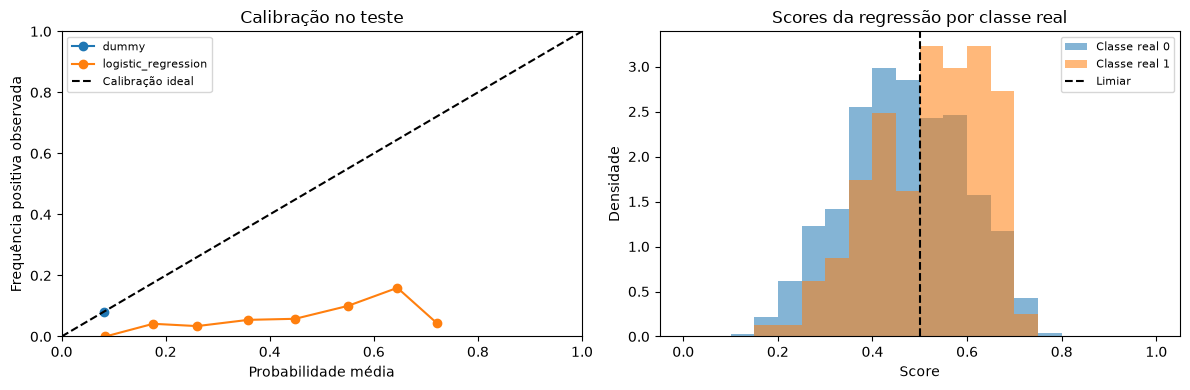

,bin,mean_probability,observed_positive_rate,support
0,0,0.084133,0.000000,1
1,1,0.175917,0.041667,24
2,2,0.260411,0.034091,176
3,3,0.358972,0.054545,385
4,4,0.448786,0.057996,569
5,5,0.549992,0.100200,499
6,6,0.645210,0.159468,301
7,7,0.720659,0.044444,45


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in models:
    calibration = evaluation_reports[name]["teste"]["calibration"]
    axes[0].plot(
        calibration["mean_probability"],
        calibration["observed_positive_rate"],
        marker="o",
        label=name,
    )
axes[0].plot([0, 1], [0, 1], "k--", label="Calibração ideal")
axes[0].set(
    title="Calibração no teste",
    xlabel="Probabilidade média",
    ylabel="Frequência positiva observada",
    xlim=(0, 1),
    ylim=(0, 1),
)
axes[0].legend(fontsize=8)
scores = evaluation_scores["logistic_regression"]["teste"]
for label in [0, 1]:
    axes[1].hist(
        scores[y_test.to_numpy() == label],
        bins=np.linspace(0, 1, 21),
        density=True,
        alpha=0.55,
        label=f"Classe real {label}",
    )
axes[1].axvline(selected_threshold, color="black", linestyle="--", label="Limiar")
axes[1].set(
    title="Scores da regressão por classe real", xlabel="Score", ylabel="Densidade"
)
axes[1].legend(fontsize=8)
fig.tight_layout()
evaluation_figures["calibration_scores"] = fig
plt.show()
display(evaluation_reports["logistic_regression"]["teste"]["calibration"])

### 6.4 Incerteza das métricas do baseline

Estimamos intervalos de 95% com 500 reamostragens estratificadas do teste,
mantendo modelo, limiar e proporção das classes fixos. Eles representam a
incerteza amostral condicionada a esse baseline; não incluem a variabilidade
de treinar outro modelo ou selecionar outro limiar. A aproximação pressupõe
observações independentes e não representa garantia de desempenho futuro.

In [12]:
confidence_intervals = evaluator.bootstrap_binary_metrics(
    y_test,
    evaluation_scores["logistic_regression"]["teste"],
    threshold=selected_threshold,
    n_resamples=500,
    confidence_level=0.95,
    random_state=RANDOM_STATE,
)
display(confidence_intervals.round(4))

,metric,estimate,lower,upper,valid_resamples,confidence_level
0,roc_auc,0.6279,0.5820,0.6730,500,0.95
1,average_precision,0.1164,0.1011,0.1393,500,0.95
2,precision,0.1183,0.1048,0.1317,500,0.95
3,recall,0.6211,0.5466,0.6957,500,0.95
4,f1,0.1988,0.1764,0.2211,500,0.95


### 6.5 Leitura dos erros e resultado do baseline

Um falso negativo é uma solicitação com dificuldade de pagamento que o
modelo não sinalizou. Um falso positivo é um alerta em uma solicitação
sem esse desfecho. Esses erros não equivalem automaticamente a perdas ou
recusas de crédito, pois não implementamos uma política de concessão.

A decisão sobre o baseline deve considerar ordenação, cobertura, alertas
falsos e calibração em conjunto. O resumo abaixo usa os resultados efetivos.

In [13]:
baseline_result = test_metrics["logistic_regression"]
dummy_result = test_metrics["dummy"]
print(
    f"Detectados {baseline_result['true_positives']} de "
    f"{baseline_result['true_positives'] + baseline_result['false_negatives']} "
    "casos positivos no teste."
)
print(
    f"Falsos positivos: {baseline_result['false_positives']}; "
    f"falsos negativos: {baseline_result['false_negatives']}."
)
print(
    f"ROC AUC: {baseline_result['roc_auc']:.3f}; "
    f"Average Precision: {baseline_result['average_precision']:.3f}; "
    f"prevalência: {baseline_result['positive_rate']:.3f}."
)
print(
    f"Brier da regressão: {baseline_result['brier_score']:.3f}; "
    f"Brier do Dummy: {dummy_result['brier_score']:.3f} (menor é melhor)."
)
train_auc = evaluation_reports["logistic_regression"]["treino"]["metrics"]["roc_auc"]
print(
    f"Diferença de ROC AUC treino/teste: {train_auc - baseline_result['roc_auc']:.3f}."
)

Detectados 100 de 161 casos positivos no teste.
Falsos positivos: 745; falsos negativos: 61.
ROC AUC: 0.628; Average Precision: 0.116; prevalência: 0.081.
Brier da regressão: 0.235; Brier do Dummy: 0.074 (menor é melhor).
Diferença de ROC AUC treino/teste: 0.010.


## 7 Persistência e verificação de recarga

Criamos **um único CSV**, `data/processed/credit_scoring.csv`, com as dez
variáveis preparadas, ID e alvo. Ele permanece nas unidades originais,
com a idade convertida em anos e as flags em 0/1. Ausências permitidas são
preservadas: imputação e normalização fazem parte do pipeline salvo.

O manifesto registra os IDs de cada partição, métricas, seed, versões e
hashes. Esses artefatos ficam em `data/processed/`, já ignorada pelo Git.
Uma nova execução substitui os artefatos locais desta demonstração.

Na inferência, a entrada deve respeitar o esquema preparado. O pipeline
serializado contém imputação, escala, encoding e estimador. O limiar é
persistido separadamente: aplicar `predict_proba` e comparar com esse valor,
pois o `predict` padrão da regressão logística usa seu próprio limiar.

A avaliação completa será salva em `data/processed/model/evaluation/`: JSON com
métricas, tabelas, curvas e calibração; CSVs com resumos e intervalos; e figuras PNG.
Os relatórios não contêm registros individuais. As métricas por classe do teste
e o caminho do relatório também ficam no manifesto para o notebook 03.


In [14]:
processed_path = project_root / "data" / "processed"
model_path = processed_path / "model"
model_path.mkdir(parents=True, exist_ok=True)
dataset_file = processed_path / "credit_scoring.csv"
pipeline_file = model_path / "baseline.joblib"
manifest_file = model_path / "manifest.json"

clean_df.to_csv(dataset_file, index=False)
joblib.dump(trained_pipeline, pipeline_file)
reloaded_pipeline = joblib.load(pipeline_file)
np.testing.assert_allclose(
    reloaded_pipeline.predict_proba(X_test),
    trained_pipeline.predict_proba(X_test),
)


def file_sha256(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


manifest = {
    "created_at": datetime.now(UTC).isoformat(),
    "source": str(train_file.relative_to(project_root)),
    "source_sha256": file_sha256(train_file),
    "dataset_sha256": file_sha256(dataset_file),
    "pipeline_sha256": file_sha256(pipeline_file),
    "sample_size": len(clean_df),
    "random_state": RANDOM_STATE,
    "features": feature_columns,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "binary_features": binary_features,
    "feature_dtypes": clean_df[feature_columns].dtypes.astype(str).to_dict(),
    "partitions": {
        name: sorted(int(value) for value in ids) for name, ids in partition_ids.items()
    },
    "model": "logistic_regression",
    "model_parameters": model_specs["logistic_regression"][1],
    "threshold": selected_threshold,
    "threshold_criterion": "maior F1 na validação em grade de 0.05 a 0.95",
    "validation_metrics_at_05": validation_metrics,
    "validation_metrics_selected_threshold": evaluate_pipeline(
        trained_pipeline, X_validation, y_validation, selected_threshold
    ),
    "test_metrics": test_metrics,
    "test_metrics_by_class": {
        name: evaluation_reports[name]["teste"]["by_class"].to_dict(orient="records")
        for name in models
    },
    "evaluation_report": "data/processed/model/evaluation/classification_report.json",
    "versions": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scikit_learn": sklearn.__version__,
        "joblib": joblib.__version__,
    },
}
manifest_file.write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False, allow_nan=False),
    encoding="utf-8",
)
display(
    pd.DataFrame(
        [
            {
                "artefato": str(path.relative_to(project_root)),
                "tamanho_kb": round(path.stat().st_size / 1_000, 1),
            }
            for path in [dataset_file, pipeline_file, manifest_file]
        ]
    )
)
print("Recarga do modelo verificada. A produção permanece reservada.")

evaluation_path = model_path / "evaluation"
evaluation_path.mkdir(parents=True, exist_ok=True)


def serializable_report(report):
    return {
        name: json.loads(value.to_json(orient="split"))
        if isinstance(value, pd.DataFrame)
        else value
        for name, value in report.items()
    }


evaluation_payload = {
    "model_sha256": manifest["pipeline_sha256"],
    "dataset_sha256": manifest["dataset_sha256"],
    "threshold": selected_threshold,
    "reports": {
        name: {split: serializable_report(report) for split, report in splits.items()}
        for name, splits in evaluation_reports.items()
    },
    "confidence_intervals": json.loads(confidence_intervals.to_json(orient="records")),
    "bootstrap": {"n_resamples": 500, "seed": RANDOM_STATE, "stratified": True},
}
(evaluation_path / "classification_report.json").write_text(
    json.dumps(evaluation_payload, indent=2, ensure_ascii=False, allow_nan=False),
    encoding="utf-8",
)
global_metrics.to_csv(evaluation_path / "global_metrics.csv")
class_metrics.to_csv(evaluation_path / "metrics_by_class.csv", index=False)
confidence_intervals.to_csv(evaluation_path / "confidence_intervals.csv", index=False)
threshold_results.to_csv(evaluation_path / "threshold_metrics.csv", index=False)
for name, figure in evaluation_figures.items():
    figure.savefig(evaluation_path / f"{name}.png", dpi=160, bbox_inches="tight")
print(f"Avaliação completa salva em {evaluation_path.relative_to(project_root)}")

,artefato,tamanho_kb
0,data/processed/credit_scoring.csv,2300.2
1,data/processed/model/baseline.joblib,8.9
2,data/processed/model/manifest.json,287.7


Recarga do modelo verificada. A produção permanece reservada.


Avaliação completa salva em data/processed/model/evaluation


## 8 Conclusões e limitações

Temos um baseline reproduzível e dez features, sem tabelas auxiliares.
O identificador e o alvo foram excluídos das entradas do modelo. A normalização
foi aprendida no treino, e o teste não participou da escolha de limiar.

O próximo notebook usará as métricas registradas para propor contratos,
cenários de drift, observabilidade e governança. Treinar o baseline, sozinho,
ainda não atende às entregas de monitoramento do Tech Challenge.

Reavaliar o uso de idade, escolaridade e possíveis proxies na análise de vieses.
Os dados são históricos, os períodos de produção serão simulados e os scores
deste modelo não foram calibrados para decisões financeiras reais.